In [1]:
import numpy as np
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.ar_model import AutoReg
from scipy.stats import norm

In [2]:
HORIZON = 6
FIGSIZE_SMALL = (4,2)
FIGSIZE_BIG = (14,8)
train_fraction=0.6

In [3]:
ROOT = Path.cwd()
DATA_ROOT = ROOT / ".." /"data" / "database" / "inflation.sqlite"

conn = sqlite3.connect(DATA_ROOT)
observations = pd.read_sql_query(
        """
        SELECT series_id, period, value
        FROM observations
        ORDER BY series_id, period;
        """,
        conn
        )

In [4]:
def MSE(y_true,y_pred):
    return np.mean((y_true-y_pred)**2)
def RMSE(y_true,y_pred):
    return np.sqrt(MSE(y_true,y_pred))
def MAE(y_true,y_pred):
    return np.mean(np.abs(y_true-y_pred))



def annual_sum_variance(coefs, sigma, horizon, variable=0):
    coefs = np.asarray(coefs, dtype=float)
    sigma = np.atleast_2d(np.asarray(sigma, dtype=float))

    p = len(coefs)
    K = sigma.shape[0]

    
    psi = np.zeros((horizon, K, K))
    psi[0] = np.eye(K)

    for j in range(1, horizon):
        for lag in range(1, min(p, j) + 1):
            psi[j] += coefs[lag - 1] @ psi[j - lag]

    
    cumulative_psi = np.cumsum(psi, axis=0)
    weights = cumulative_psi[:, variable, :]

    variance = sum(w @ sigma @ w for w in weights)

    return float(variance)


def add_prediction_intervals(results, variances):
    out = results.copy()

    variances = np.asarray(variances, dtype=float)
    
    out["annual_log_sd"] = np.sqrt(variances)

    for level in [80, 95]:
        alpha = 1 - level / 100
        radius = norm.ppf(1 - alpha / 2) * out["annual_log_sd"]

        out[f"lower_{level}"] = out["annual_log_forecast"] - radius
        out[f"upper_{level}"] = out["annual_log_forecast"] + radius

    return out

In [5]:
observations["period"] = pd.PeriodIndex(data = observations["period"], freq="M")
levels = observations.pivot(index="period",columns=["series_id"],values="value")
column_order = ["hicp_total","hicp_energy","industrial_production","euribor_3m"]
levels=levels.reindex(columns=column_order).sort_index()

levels.index = levels.index.to_timestamp()
export_path = "../data/preprocessed/macro_levels_data.csv"
levels.to_csv(export_path, index=True, index_label="Time")
print(f"DataFrame esportato in: {export_path}")

DataFrame esportato in: ../data/preprocessed/macro_levels_data.csv


In [6]:
prices = np.log(levels["hicp_total"])
energy_price = np.log(levels["hicp_energy"])
industrial_production = np.log(levels["industrial_production"])
euribor = levels["euribor_3m"].iloc[1:]

monthly_inflation=prices.diff(1).dropna()
monthly_energy_inflation = energy_price.diff(1).dropna()
monthly_industrial_growth = industrial_production.diff(1).dropna()


annual_inflation =prices.diff(12).dropna()

split_index = int(train_fraction*len(monthly_inflation))

monthly_inflation_train = monthly_inflation.iloc[:split_index]
monthly_inflation_test = monthly_inflation.iloc[split_index:]

monthly_energy_inflation_train = monthly_energy_inflation.iloc[:split_index]
monthly_energy_inflation_test = monthly_energy_inflation.iloc[split_index:]

monthly_industrial_growth_train = monthly_industrial_growth.iloc[:split_index]
monthly_industrial_growth_test = monthly_industrial_growth.iloc[split_index:]

euribor_train = euribor.iloc[:split_index]
euribor_test = euribor.iloc[split_index:]


train_data = pd.DataFrame({
    'Inflation': monthly_inflation_train,
    'Energy_Inflation': monthly_energy_inflation_train,
    'Industrial_Growth': monthly_industrial_growth_train,
    'Euribor': euribor_train
})

test_data = pd.DataFrame({
    'Inflation': monthly_inflation_test,
    'Energy_Inflation': monthly_energy_inflation_test,
    'Industrial_Growth': monthly_industrial_growth_test,
    'Euribor': euribor_test
})

full_data = pd.DataFrame({
    'Inflation': monthly_inflation,
    'Energy_Inflation': monthly_energy_inflation,
    'Industrial_Growth': monthly_industrial_growth,
    'Euribor': euribor
})

In [7]:
predictions_persistence = []
predictions_persistence_annual = []
forecast_origins = []

assert 1 <= HORIZON <= 12

for i in range(len(monthly_inflation_test)):

    target_position = split_index + i
    origin_position = target_position - HORIZON

    # Ultima variazione mensile disponibile all'origine.
    last_monthly_inflation = monthly_inflation.iloc[origin_position]

    # Tutti i mesi futuri sono previsti uguali all'ultimo osservato.
    monthly_path = np.repeat(last_monthly_inflation, HORIZON)

    predictions_persistence.append(monthly_path[-1])

    # Parte già osservata della variazione annuale.
    n_known = 12 - HORIZON
    known_months = monthly_inflation.iloc[
        origin_position - n_known + 1 : origin_position + 1
    ]

    assert len(known_months) == n_known

    annual_prediction = known_months.sum() + monthly_path.sum()
    predictions_persistence_annual.append(annual_prediction)

    origin_date = monthly_inflation.index[origin_position]
    target_date = monthly_inflation.index[target_position]


    forecast_origins.append(origin_date)



naive_monthly_inflation_forecast = pd.Series(
    predictions_persistence,
    index=monthly_inflation_test.index,
    name="monthly_forecast",
)

naive_annual_inflation_forecast = pd.Series(
    predictions_persistence_annual,
    index=monthly_inflation_test.index,
    name="annual_log_forecast",
)

annual_inflation_real_test = (
    monthly_inflation
    .rolling(12)
    .sum()
    .loc[monthly_inflation_test.index]
)

persistence_results = pd.DataFrame(
    {
        "origin": forecast_origins,
        "monthly_actual": monthly_inflation_test,
        "monthly_forecast": naive_monthly_inflation_forecast,
        "annual_log_actual": annual_inflation_real_test,
        "annual_log_forecast": naive_annual_inflation_forecast,
    },
    index=monthly_inflation_test.index,
).rename_axis("target")

display(persistence_results.head())

,origin,monthly_actual,monthly_forecast,annual_log_actual,annual_log_forecast
target,,,,,
2015-08-01,2015-02-01,0.000000,0.006271,0.004382,0.029327
2015-09-01,2015-03-01,0.002055,0.011525,0.002055,0.067991
2015-10-01,2015-04-01,0.001283,0.004240,0.003853,0.029035
2015-11-01,2015-05-01,-0.004367,0.002817,0.001288,0.025115
2015-12-01,2015-06-01,0.000129,0.000128,0.002449,0.010142


In [8]:
predictions_ar = []
predictions_ar_annual = []
forecast_origins = []

assert 1 <= HORIZON <= 12

for i in range(len(monthly_inflation_test)):

    target_position = split_index + i
    origin_position = target_position - HORIZON

    # Campione disponibile all'origine, inclusa.
    monthly_inflation_train_rolling = monthly_inflation.iloc[:origin_position + 1]

    
    ar_mod = AutoReg(
        monthly_inflation_train_rolling,
        lags=6,
        trend="c",
        seasonal=False,
        hold_back=6,
        missing="raise",
    )
    res = ar_mod.fit()

    
    prediction = res.forecast(steps=HORIZON)

    # Previsione della variazione mensile al mese obiettivo.
    predictions_ar.append(prediction.iloc[-1])

    # Parte già osservata della variazione annuale.
    n_known = 12 - HORIZON
    known_months = monthly_inflation.iloc[
        origin_position - n_known + 1 : origin_position + 1
    ]


    # Inflazione annuale logaritmica nel mese obiettivo.
    annual_prediction = known_months.sum() + prediction.sum()
    predictions_ar_annual.append(annual_prediction)

    origin_date = monthly_inflation.index[origin_position]
    target_date = monthly_inflation.index[target_position]


    forecast_origins.append(origin_date)

predictions_ar_series = pd.Series(
    predictions_ar,
    index=monthly_inflation_test.index,
    name="monthly_forecast",
)

predictions_ar_annual_series = pd.Series(
    predictions_ar_annual,
    index=monthly_inflation_test.index,
    name="annual_log_forecast",
)

annual_inflation_real_test = (
    monthly_inflation
    .rolling(12)
    .sum()
    .loc[monthly_inflation_test.index]
)

ar_results = pd.DataFrame(
    {
        "origin": forecast_origins,
        "monthly_actual": monthly_inflation_test,
        "monthly_forecast": predictions_ar_series,
        "annual_log_actual": annual_inflation_real_test,
        "annual_log_forecast": predictions_ar_annual_series,
    },
    index=monthly_inflation_test.index,
).rename_axis("target")

display(ar_results.head())

,origin,monthly_actual,monthly_forecast,annual_log_actual,annual_log_forecast
target,,,,,
2015-08-01,2015-02-01,0.000000,0.004049,0.004382,-0.004379
2015-09-01,2015-03-01,0.002055,0.009127,0.002055,0.003843
2015-10-01,2015-04-01,0.001283,0.004026,0.003853,0.010040
2015-11-01,2015-05-01,-0.004367,0.003297,0.001288,0.016147
2015-12-01,2015-06-01,0.000129,0.000581,0.002449,0.018150


In [9]:
annual_inflation_real = monthly_inflation.rolling(12).sum()

var_results = []

for target_position in range(split_index, len(full_data)):

    origin_position = target_position - HORIZON

    train_data_rolling = full_data.iloc[:origin_position + 1]

    model = VAR(train_data_rolling)
    fitted_model = model.fit(maxlags=8, ic="aic")
    lag_order = fitted_model.k_ar

    if lag_order == 0:
        # VAR con sola intercetta.
        monthly_path = np.repeat(
            fitted_model.intercept[0], HORIZON
        )
    else:
        last_values = train_data_rolling.to_numpy()[-lag_order:]

        forecast_path = fitted_model.forecast(
            y=last_values,
            steps=HORIZON,
        )

        monthly_path = forecast_path[:, 0]

    n_known = 12 - HORIZON

    known_months = monthly_inflation.iloc[
        origin_position - n_known + 1 : origin_position + 1
    ]


    annual_log_forecast = (
        known_months.sum() + monthly_path.sum()
    )

    origin_date = full_data.index[origin_position]
    target_date = full_data.index[target_position]


    var_results.append({
        "origin": origin_date,
        "target": target_date,
        "selected_p": lag_order,
        "monthly_actual": monthly_inflation.iloc[target_position],
        "monthly_forecast": monthly_path[-1],
        "annual_log_actual": annual_inflation_real.iloc[target_position],
        "annual_log_forecast": annual_log_forecast,
    })

var_results = pd.DataFrame(var_results).set_index("target")
display(var_results.head())

,origin,selected_p,monthly_actual,monthly_forecast,annual_log_actual,annual_log_forecast
target,,,,,,
2015-08-01,2015-02-01,6,0.000000,0.005249,0.004382,0.006777
2015-09-01,2015-03-01,6,0.002055,0.009004,0.002055,0.011147
2015-10-01,2015-04-01,6,0.001283,0.002977,0.003853,0.013970
2015-11-01,2015-05-01,6,-0.004367,0.000325,0.001288,0.016776
2015-12-01,2015-06-01,6,0.000129,-0.000792,0.002449,0.015508


In [10]:
expected_targets = monthly_inflation.index[split_index:]

persistence_variances = []
ar_variances = []
var_variances = []

for target_position in range(split_index, len(full_data)):

    origin_position = target_position - HORIZON
    target_date = full_data.index[target_position]
    origin_date = full_data.index[origin_position]

    y_train = monthly_inflation.iloc[:origin_position + 1]
    z_train = full_data.iloc[:origin_position + 1]

    known_part = monthly_inflation.iloc[
        target_position - 11 : origin_position + 1
    ].sum()

    # Random walk senza drift
    innovations = np.diff(y_train.to_numpy())
    sigma2_persistence = np.mean(innovations**2)

    persistence_variances.append(
        sigma2_persistence
        * np.sum(np.arange(1, HORIZON + 1, dtype=float)**2)
    )

    persistence_mean = known_part + HORIZON * y_train.iloc[-1]

    # ------ AR(6) ----
    ar_fit = AutoReg(
        y_train,
        lags=6,
        trend="c",
        seasonal=False,
        hold_back=6,
        missing="raise",
    ).fit()

    ar_coefs = np.asarray(ar_fit.params)[1:].reshape(6, 1, 1)

    ar_variances.append(
        annual_sum_variance(
            ar_coefs,
            np.array([[float(ar_fit.sigma2)]]),
            HORIZON,
        )
    )

    ar_mean = known_part + np.asarray(
        ar_fit.forecast(steps=HORIZON)
    ).sum()


    # ---------- VAR ----------
    var_fit = VAR(z_train).fit(maxlags=8, ic="aic")
    p = var_fit.k_ar

    assert p == var_results.loc[target_date, "selected_p"]

    var_variances.append(
        annual_sum_variance(
            var_fit.coefs,
            var_fit.sigma_u,
            HORIZON,
            variable=0,
        )
    )

    if p == 0:
        var_path = np.repeat(var_fit.intercept[0], HORIZON)
    else:
        var_path = var_fit.forecast(
            z_train.to_numpy()[-p:],
            steps=HORIZON,
        )[:, 0]


persistence_results = add_prediction_intervals(
    persistence_results, persistence_variances
)
ar_results = add_prediction_intervals(ar_results, ar_variances)
var_results = add_prediction_intervals(var_results, var_variances)

In [11]:
print(
    "RMSE MONTHLY PERSISTENCE:",
    RMSE(100*monthly_inflation_test, 100*naive_monthly_inflation_forecast),
)
print(
    "MAE MONTHLY PERSISTENCE:",
    MAE(100*monthly_inflation_test, 100*naive_monthly_inflation_forecast),
)

print(
    "RMSE ANNUAL LOG PERSISTENCE:",
    RMSE(100*annual_inflation_real_test, 100*naive_annual_inflation_forecast),
)
print(
    "MAE ANNUAL LOG PERSISTENCE:",
    MAE(100*annual_inflation_real_test, 100*naive_annual_inflation_forecast),
)

RMSE MONTHLY PERSISTENCE: 0.5316975545851926
MAE MONTHLY PERSISTENCE: 0.4289965596130969
RMSE ANNUAL LOG PERSISTENCE: 3.101202094271445
MAE ANNUAL LOG PERSISTENCE: 2.338022589400549


In [12]:
print(
    "RMSE MONTHLY AR:",
    RMSE(monthly_inflation_test, 100*ar_results["monthly_forecast"]),
)
print(
    "MAE MONTHLY AR:",
    MAE(monthly_inflation_test, 100*ar_results["monthly_forecast"]),
)

print(
    "RMSE ANNUAL LOG AR:",
    RMSE(100*annual_inflation_real_test, 100*ar_results["annual_log_forecast"]),
)
print(
    "MAE ANNUAL LOG AR:",
    MAE(100*annual_inflation_real_test, 100*ar_results["annual_log_forecast"]),
)

RMSE MONTHLY AR: 0.35719735624720167
MAE MONTHLY AR: 0.2793785932121651
RMSE ANNUAL LOG AR: 1.4067007041314687
MAE ANNUAL LOG AR: 1.075489997224355


In [13]:
print(
    "RMSE MONTHLY VAR:",
    RMSE(monthly_inflation_test, 100*var_results["monthly_forecast"]),
)
print(
    "MAE MONTHLY VAR:",
    MAE(monthly_inflation_test, 100*var_results["monthly_forecast"]),
)

print(
    "RMSE ANNUAL LOG VAR:",
    RMSE(100*annual_inflation_real_test, 100*var_results["annual_log_forecast"]),
)
print(
    "MAE ANNUAL LOG VAR:",
    MAE(100*annual_inflation_real_test, 100*var_results["annual_log_forecast"]),
)

RMSE MONTHLY VAR: 0.3714172905087726
MAE MONTHLY VAR: 0.28037442488697556
RMSE ANNUAL LOG VAR: 1.605132232973242
MAE ANNUAL LOG VAR: 1.131880356533386


In [14]:
CSV_PATH = Path(f"../scripts/results/bvar_forecasts_h{HORIZON}.csv")

bvar_results = pd.read_csv(
    CSV_PATH,
    parse_dates=["Origin", "Target"],
)

for column in ["Origin", "Target"]:
    bvar_results[column] = (
        bvar_results[column].dt.to_period("M")
    )

bvar_results = bvar_results.sort_values("Target").reset_index(drop=True)
display(bvar_results.head())

,Origin,Target,MonthlyActual,MonthlyForecast,AnnualLogActual,AnnualLogForecast,Lower80,Upper80,Lower95,Upper95,AnnualMCSE,Seconds,Horizon,LagOrder,NumDraws
0,2015-02,2015-08,0.000000,0.002607,0.004382,0.005370,-0.004946,0.015827,-0.010602,0.021548,0.000058,1.015163,6,12,20000
1,2015-03,2015-09,0.002055,0.005917,0.002055,0.008086,-0.002049,0.018172,-0.007333,0.023845,0.000056,0.875711,6,12,20000
2,2015-04,2015-10,0.001283,0.002214,0.003853,0.010173,0.000127,0.020204,-0.005362,0.025793,0.000056,0.871891,6,12,20000
3,2015-05,2015-11,-0.004367,0.000689,0.001288,0.014271,0.004307,0.024281,-0.001179,0.029633,0.000056,0.786018,6,12,20000
4,2015-06,2015-12,0.000129,0.000074,0.002449,0.014614,0.004776,0.024261,-0.000689,0.029591,0.000054,0.775208,6,12,20000


In [15]:
expected_targets = pd.PeriodIndex(
    monthly_inflation.index[split_index:],
    freq="M",
    name="target",
)

bvar_annual_results = (
    bvar_results
    .set_index("Target")
    .rename(columns={
        "Origin": "origin",
        "AnnualLogActual": "annual_log_actual",
        "AnnualLogForecast": "annual_log_forecast",
        "Lower80": "lower_80",
        "Upper80": "upper_80",
        "Lower95": "lower_95",
        "Upper95": "upper_95",
    })
)

assert bvar_results["Horizon"].eq(HORIZON).all()

annual_results = {
    "Persistence": persistence_results,
    "AR": ar_results,
    "VAR": var_results,
    "BVAR": bvar_annual_results,
}

for model, results in annual_results.items():
    results = results.copy()

    results.index = pd.PeriodIndex(
        results.index,
        freq="M",
        name="target",
    )
    results["origin"] = pd.PeriodIndex(
        results["origin"],
        freq="M",
    )

    annual_results[model] = results.sort_index()

for model, results in annual_results.items():
    assert results.index.is_unique, f"{model}: target duplicati"

    assert results.index.equals(expected_targets), (
        f"{model}: mesi obiettivo diversi da quelli attesi."
    )

    origins = pd.PeriodIndex(results["origin"], freq="M")

    assert (origins + HORIZON).equals(results.index), (
        f"{model}: distanza origine-target errata."
    )

bvar_annual_results = annual_results["BVAR"]

print("Date e valori osservati correttamente allineati.")

Date e valori osservati correttamente allineati.


In [16]:
actual = 100 * bvar_results["AnnualLogActual"].to_numpy()
forecast = 100 * bvar_results["AnnualLogForecast"].to_numpy()

lower80 = 100 * bvar_results["Lower80"].to_numpy()
upper80 = 100 * bvar_results["Upper80"].to_numpy()
lower95 = 100 * bvar_results["Lower95"].to_numpy()
upper95 = 100 * bvar_results["Upper95"].to_numpy()

errors = actual - forecast

bvar_metrics = pd.DataFrame([{
    "model": "BVAR",
    "horizon": HORIZON,
    "n": len(errors),
    "MAE": np.mean(np.abs(errors)),
    "RMSE": np.sqrt(np.mean(errors**2)),
    "coverage_80": np.mean((actual >= lower80) & (actual <= upper80)),
    "coverage_95": np.mean((actual >= lower95) & (actual <= upper95)),
}])

display(bvar_metrics.round(4))

,model,horizon,n,MAE,RMSE,coverage_80,coverage_95
0,BVAR,6,125,0.9707,1.4641,0.736,0.872


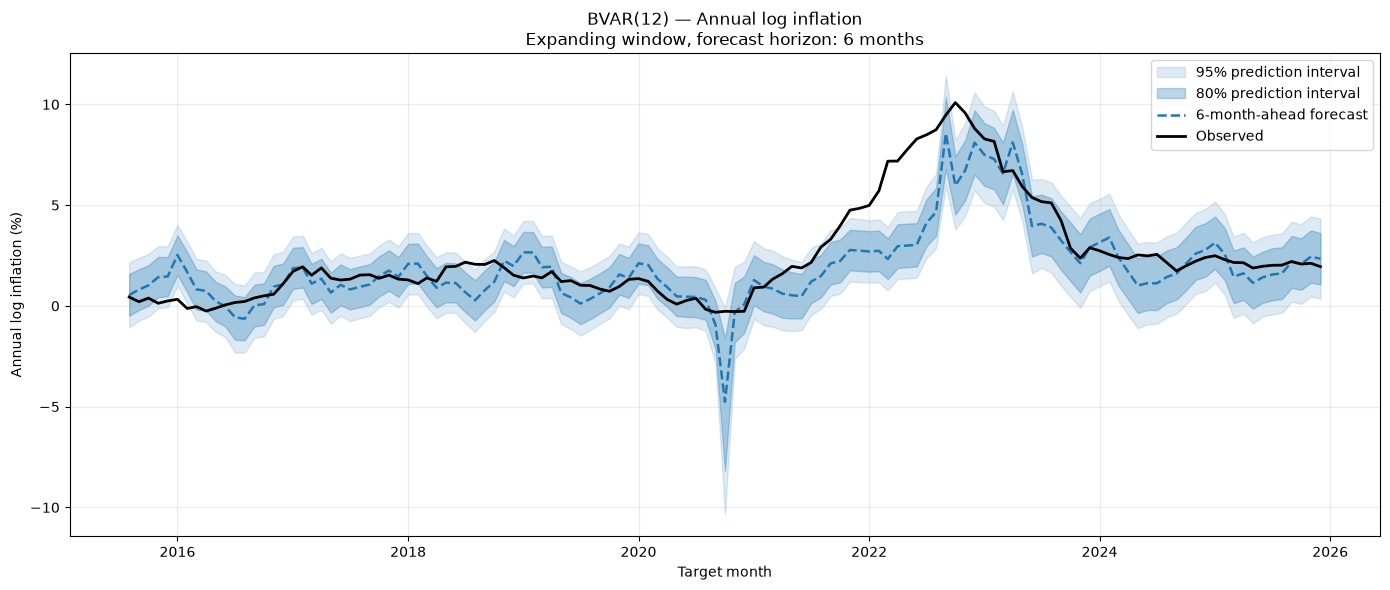

In [17]:
dates = pd.PeriodIndex(bvar_results["Target"]).to_timestamp()
lag_order = int(bvar_results["LagOrder"].iloc[0])

fig, ax = plt.subplots(figsize=(14, 6))

ax.fill_between(
    dates, lower95, upper95,
    color="tab:blue", alpha=0.15,
    label="95% prediction interval",
)

ax.fill_between(
    dates, lower80, upper80,
    color="tab:blue", alpha=0.30,
    label="80% prediction interval",
)

ax.plot(
    dates, forecast,
    color="tab:blue", linestyle="--", linewidth=1.8,
    label=f"{HORIZON}-month-ahead forecast",
)

ax.plot(
    dates, actual,
    color="black", linewidth=2,
    label="Observed",
)

ax.set_title(
    f"BVAR({lag_order}) — Annual log inflation\n"
    f"Expanding window, forecast horizon: {HORIZON} months"
)
ax.set_xlabel("Target month")
ax.set_ylabel("Annual log inflation (%)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

In [18]:
metric_rows = []

for model, results in annual_results.items():

    actual = 100 * results["annual_log_actual"].to_numpy()
    forecast = 100 * results["annual_log_forecast"].to_numpy()
    error = actual - forecast

    for level in [80, 95]:
        alpha = 1 - level / 100

        lower = 100 * results[f"lower_{level}"].to_numpy()
        upper = 100 * results[f"upper_{level}"].to_numpy()

        width = upper - lower
        covered = (actual >= lower) & (actual <= upper)

        score = (
            width
            + (2 / alpha) * np.maximum(lower - actual, 0)
            + (2 / alpha) * np.maximum(actual - upper, 0)
        )

        metric_rows.append({
            "model": model,
            "horizon": HORIZON,
            "level": level,
            "n": len(actual),
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error**2)),
            "coverage": covered.mean(),
            "mean_width": width.mean(),
            "interval_score": score.mean(),
        })

annual_metrics = pd.DataFrame(metric_rows)

display(annual_metrics.round(4))
print(annual_metrics.round(4).to_latex())

,model,horizon,level,n,MAE,RMSE,coverage,mean_width,interval_score
0,Persistence,6,80,125,2.3380,3.1012,0.968,14.7290,15.3306
1,Persistence,6,95,125,2.3380,3.1012,1.000,22.5261,22.5261
2,AR,6,80,125,1.0755,1.4067,0.592,2.0753,5.4387
3,AR,6,95,125,1.0755,1.4067,0.808,3.1739,10.8490
4,VAR,6,80,125,1.1319,1.6051,0.552,2.1109,6.3172
5,VAR,6,95,125,1.1319,1.6051,0.776,3.2284,13.4625
6,BVAR,6,80,125,0.9707,1.4641,0.736,2.3396,5.4113
7,BVAR,6,95,125,0.9707,1.4641,0.872,3.6118,11.2802


\begin{tabular}{llrrrrrrrr}
\toprule
 & model & horizon & level & n & MAE & RMSE & coverage & mean_width & interval_score \\
\midrule
0 & Persistence & 6 & 80 & 125 & 2.338000 & 3.101200 & 0.968000 & 14.729000 & 15.330600 \\
1 & Persistence & 6 & 95 & 125 & 2.338000 & 3.101200 & 1.000000 & 22.526100 & 22.526100 \\
2 & AR & 6 & 80 & 125 & 1.075500 & 1.406700 & 0.592000 & 2.075300 & 5.438700 \\
3 & AR & 6 & 95 & 125 & 1.075500 & 1.406700 & 0.808000 & 3.173900 & 10.849000 \\
4 & VAR & 6 & 80 & 125 & 1.131900 & 1.605100 & 0.552000 & 2.110900 & 6.317200 \\
5 & VAR & 6 & 95 & 125 & 1.131900 & 1.605100 & 0.776000 & 3.228400 & 13.462500 \\
6 & BVAR & 6 & 80 & 125 & 0.970700 & 1.464100 & 0.736000 & 2.339600 & 5.411300 \\
7 & BVAR & 6 & 95 & 125 & 0.970700 & 1.464100 & 0.872000 & 3.611800 & 11.280200 \\
\bottomrule
\end{tabular}



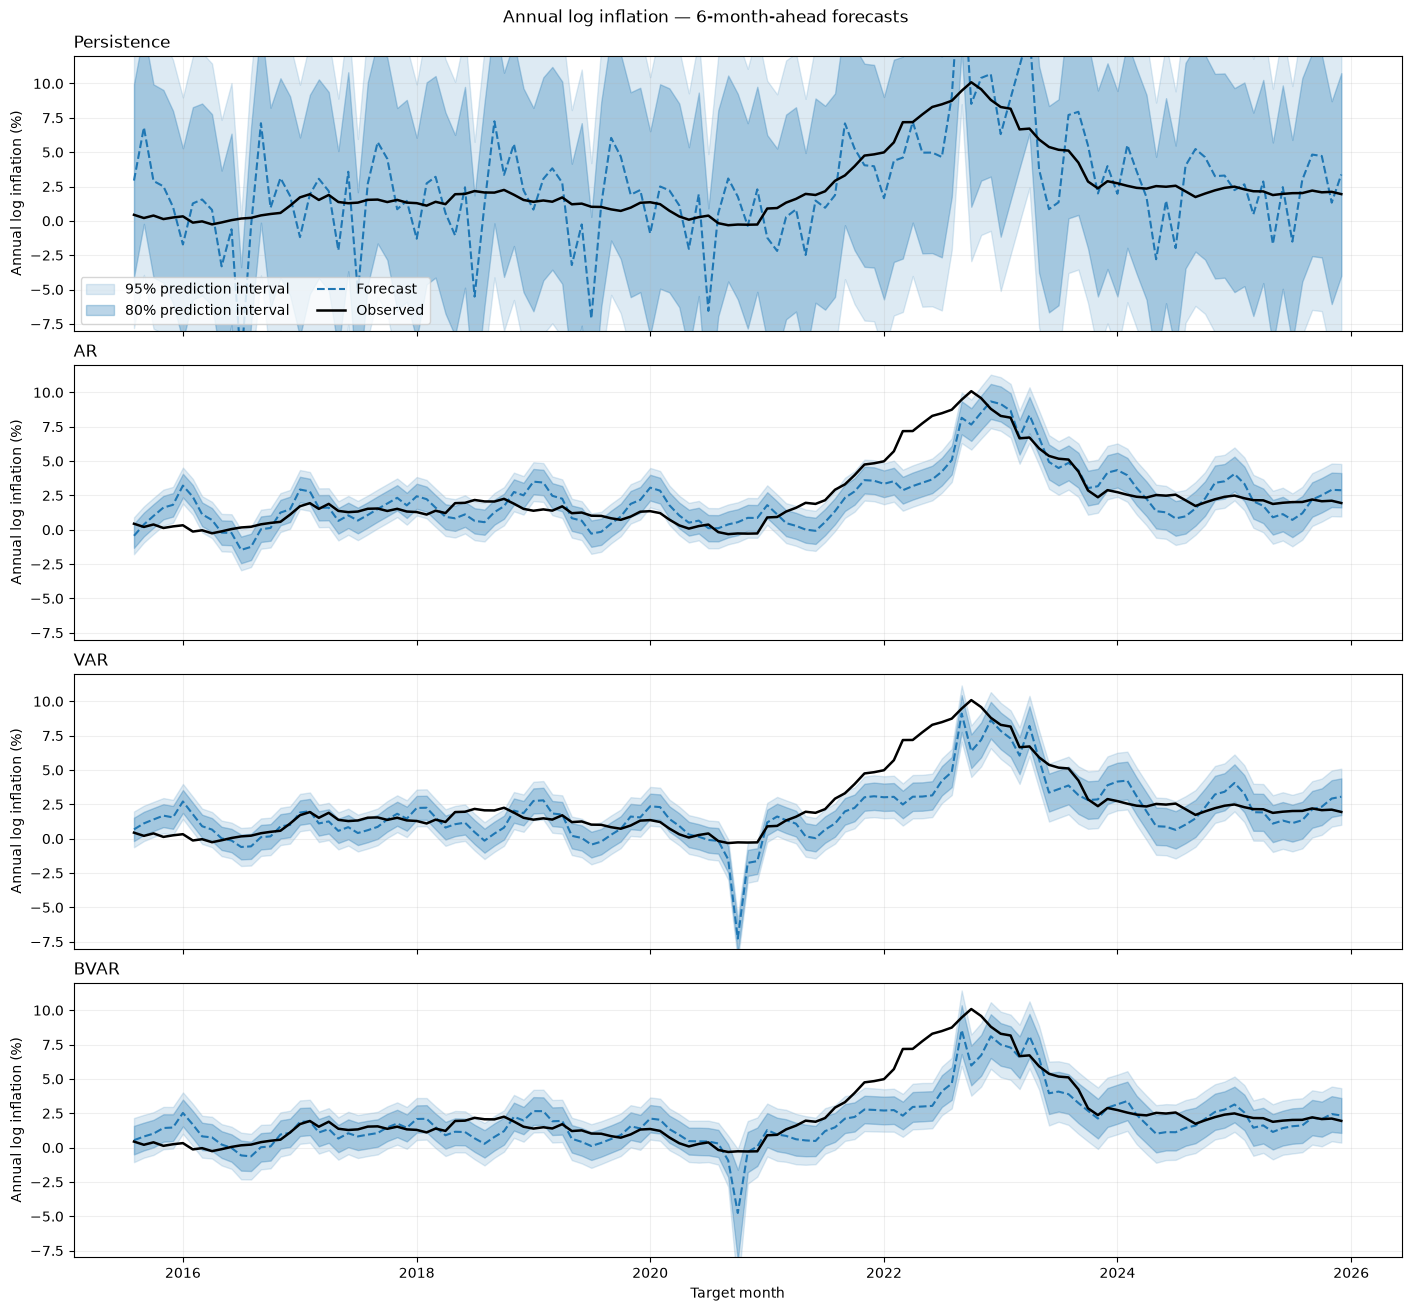

In [19]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 13),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, (model, results) in zip(axes, annual_results.items()):

    dates = results.index.to_timestamp()

    ax.fill_between(
        dates,
        100 * results["lower_95"].to_numpy(),
        100 * results["upper_95"].to_numpy(),
        color="tab:blue", alpha=0.15,
        label="95% prediction interval",
    )

    ax.fill_between(
        dates,
        100 * results["lower_80"].to_numpy(),
        100 * results["upper_80"].to_numpy(),
        color="tab:blue", alpha=0.30,
        label="80% prediction interval",
    )

    ax.plot(
        dates,
        100 * results["annual_log_forecast"].to_numpy(),
        color="tab:blue", linestyle="--",
        label="Forecast",
    )

    ax.plot(
        dates,
        100 * results["annual_log_actual"].to_numpy(),
        color="black", linewidth=1.8,
        label="Observed",
    )

    ax.set_title(model, loc="left")
    ax.set_ylabel("Annual log inflation (%)")
    ax.set_ylim([-8,12])
    ax.grid(alpha=0.2)

axes[0].legend(ncol=2, loc="best")
axes[-1].set_xlabel("Target month")

fig.suptitle(
    f"Annual log inflation — {HORIZON}-month-ahead forecasts"
)

output_dir = ROOT / "results"
output_dir.mkdir(parents=True, exist_ok=True)

annual_metrics.to_csv(
    output_dir / f"annual_metrics_h{HORIZON}.csv",
    index=False,
)
plt.savefig(f"../results/figures/Forecasting_Comparison_{HORIZON}months.png")
plt.show()

In [20]:
import matplotlib.dates as mdates

LAGS = 36
ROLLING_WINDOW = 12


features = ["Inflation", "Energy_Inflation", "Industrial_Growth", "Euribor"]
eda_data = train_data.loc[:, features].copy().sort_index()

if isinstance(eda_data.index, pd.PeriodIndex):
    monthly_index = eda_data.index.asfreq("M")
else:
    monthly_index = pd.DatetimeIndex(eda_data.index).to_period("M")


eda_data.index = monthly_index.to_timestamp()
eda_data.loc[:, features[:3]] = 100 * eda_data.loc[:, features[:3]]

titles = {
    "Inflation": "Total HICP: monthly log inflation",
    "Energy_Inflation": "Energy HICP: monthly log inflation",
    "Industrial_Growth": "Industrial production: monthly log growth",
    "Euribor": "Three-month Euribor",
}
units = {feature: "Monthly log change (x100)" for feature in features[:3]}
units["Euribor"] = "Rate (%)"

def format_time_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.25)



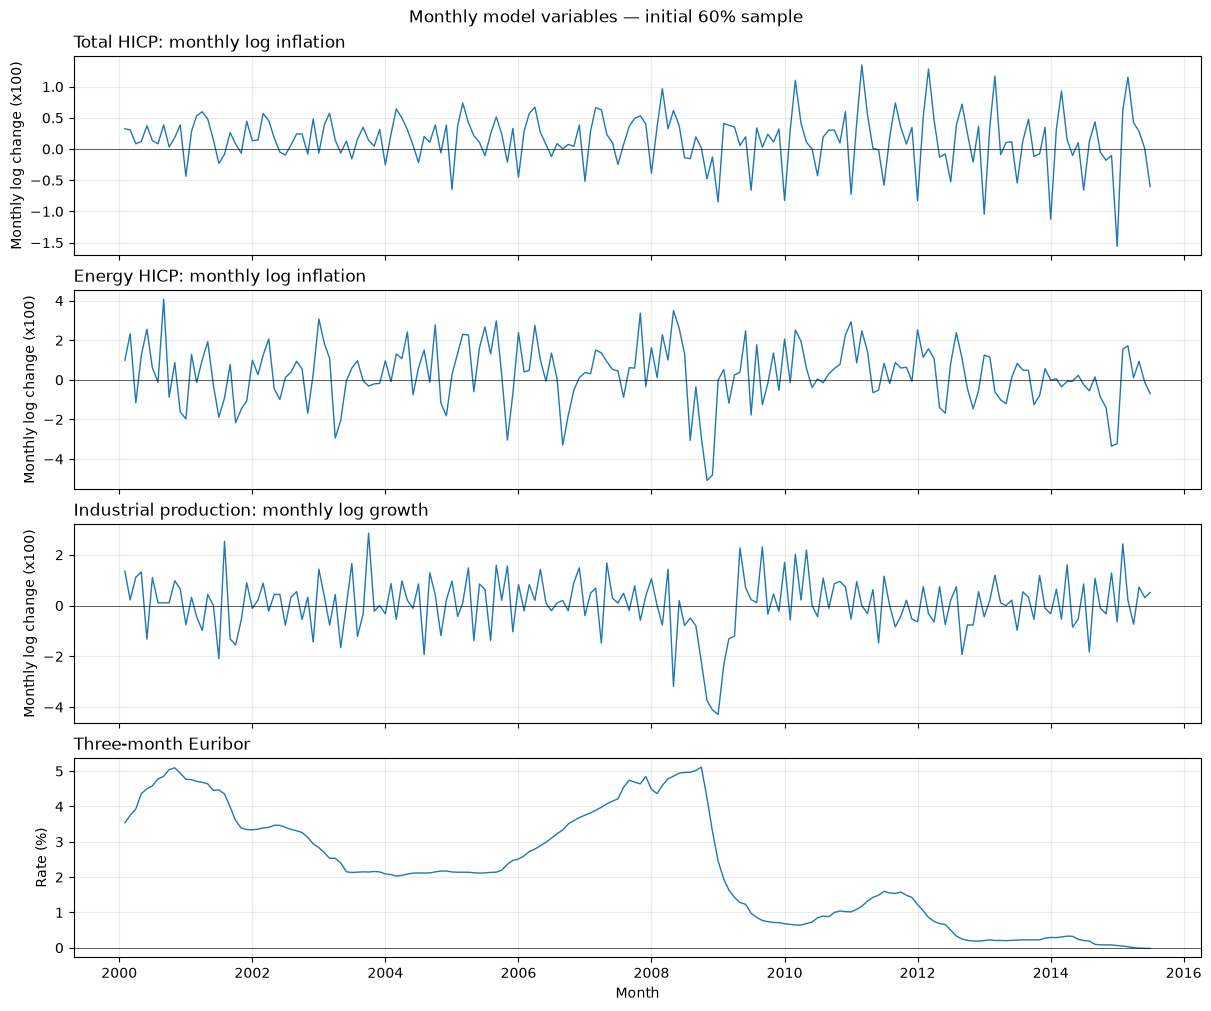

In [21]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True,
                         constrained_layout=True)

for ax, feature in zip(axes, features):
    series = eda_data[feature]
    ax.plot(series.index, series, color="tab:blue", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.7, alpha=0.6)
    ax.set_title(titles[feature], loc="left")
    ax.set_ylabel(units[feature])
    format_time_axis(ax)

axes[-1].set_xlabel("Month")
fig.suptitle("Monthly model variables — initial 60% sample")
plt.savefig("../results/figures/time_plots.png")
plt.show()


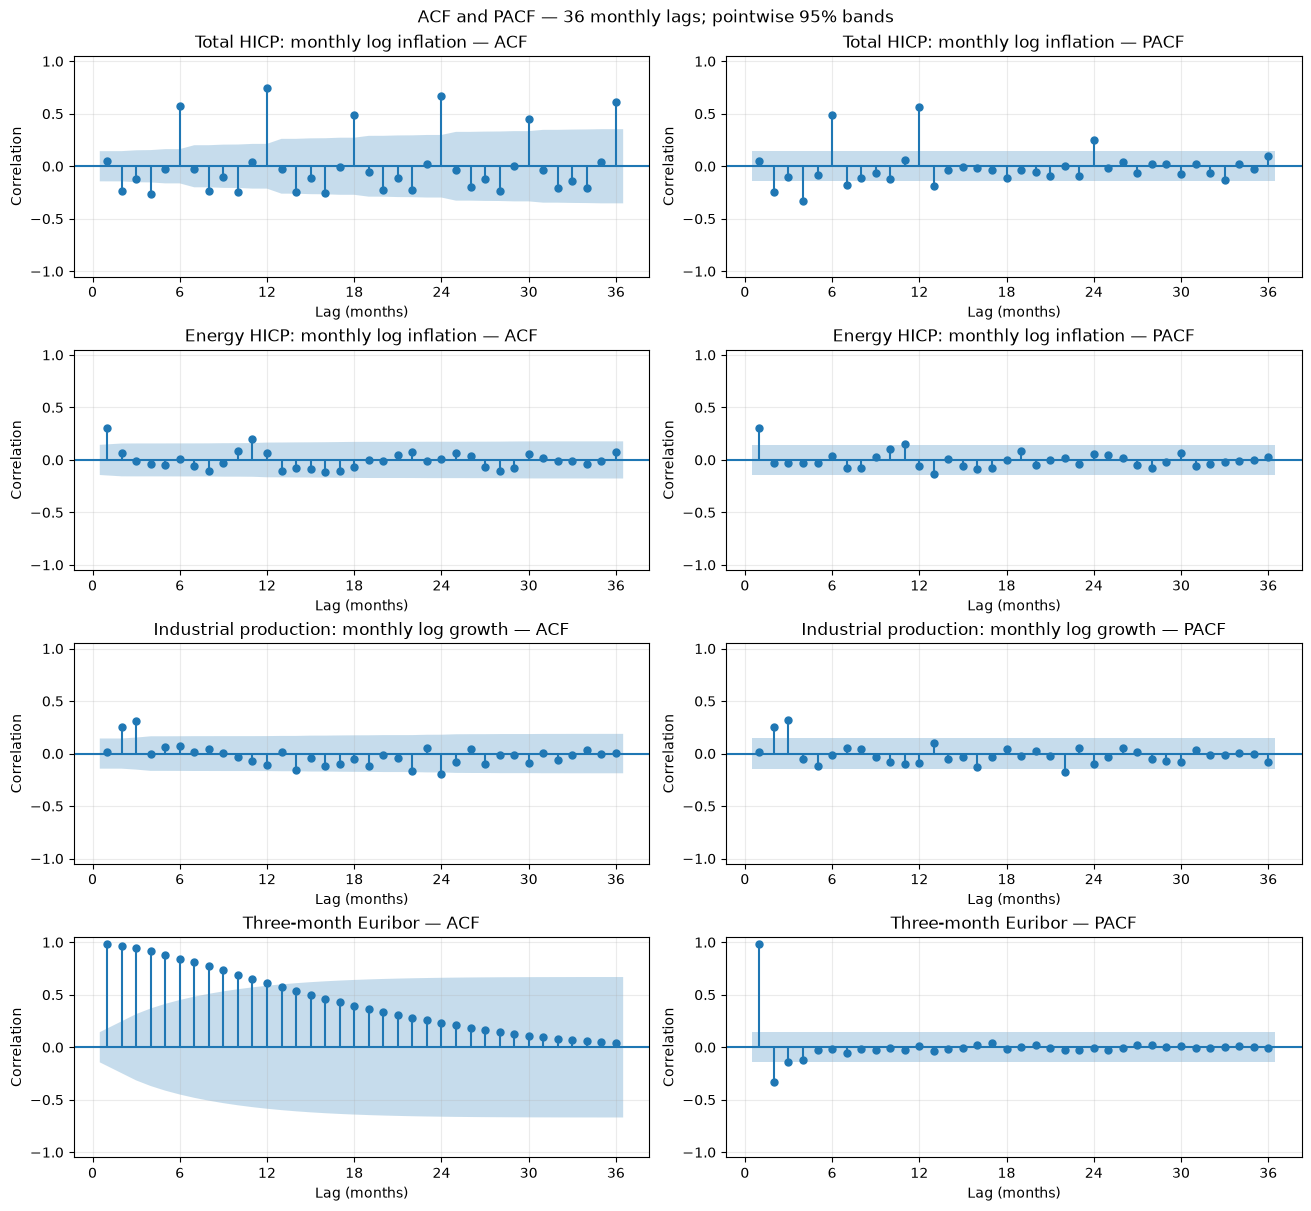

In [22]:
fig, axes = plt.subplots(4, 2, figsize=(13, 12),
                         constrained_layout=True)

for row, feature in enumerate(features):
    series = eda_data[feature]
    plot_acf(series, lags=LAGS, zero=False, alpha=0.05,
             ax=axes[row, 0], title=f"{titles[feature]} — ACF")
    plot_pacf(series, lags=LAGS, zero=False, alpha=0.05, method="ywm",
              ax=axes[row, 1], title=f"{titles[feature]} — PACF")
    for ax in axes[row]:
        ax.set_xlabel("Lag (months)")
        ax.set_ylabel("Correlation")
        ax.set_xticks(np.arange(0, LAGS + 1, 6))
        ax.set_ylim(-1.05, 1.05)
        ax.grid(alpha=0.25)

fig.suptitle("ACF and PACF — 36 monthly lags; pointwise 95% bands")
plt.savefig("../results/figures/acf_pacf.png")
plt.show()


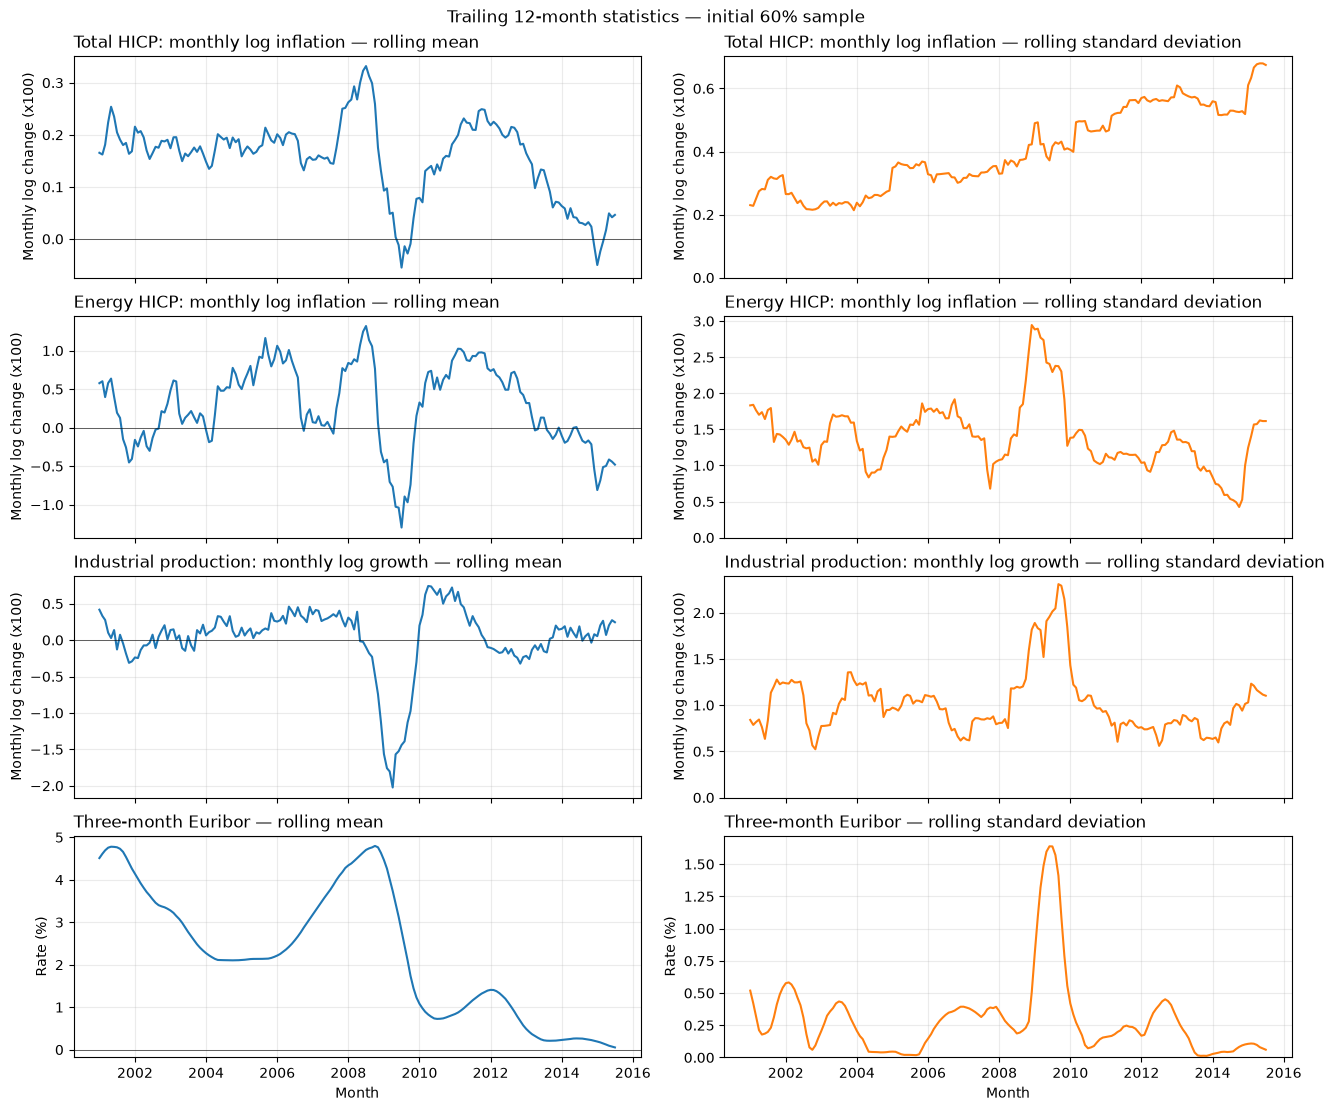

In [23]:
rolling_mean = eda_data.rolling(
    window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW
).mean()
rolling_std = eda_data.rolling(
    window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW
).std(ddof=1)

fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True,
                         constrained_layout=True)

for row, feature in enumerate(features):
    axes[row, 0].plot(eda_data.index, rolling_mean[feature],
                      color="tab:blue", linewidth=1.5)
    axes[row, 1].plot(eda_data.index, rolling_std[feature],
                      color="tab:orange", linewidth=1.5)
    axes[row, 0].set_title(f"{titles[feature]} — rolling mean", loc="left")
    axes[row, 1].set_title(f"{titles[feature]} — rolling standard deviation",
                           loc="left")
    axes[row, 0].axhline(0, color="black", linewidth=0.7, alpha=0.6)
    axes[row, 1].set_ylim(bottom=0)
    for ax in axes[row]:
        ax.set_ylabel(units[feature])
        format_time_axis(ax)

for ax in axes[-1]:
    ax.set_xlabel("Month")

fig.suptitle(f"Trailing {ROLLING_WINDOW}-month statistics — initial 60% sample")
plt.savefig("../results/figures/rolling_stats.png")
plt.show()


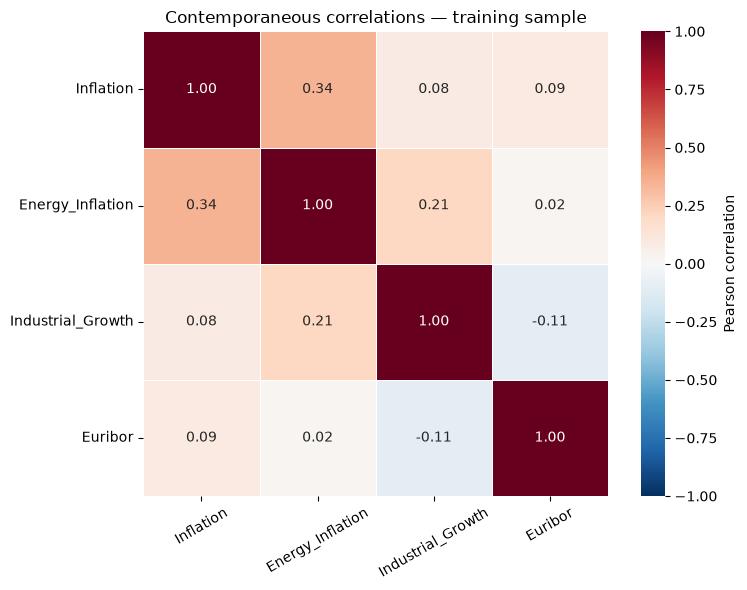

In [24]:
import seaborn as sns

correlation = train_data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)

ax.set_title("Contemporaneous correlations — training sample")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
plt.savefig("../results/figures/correlation_matrix.png")
plt.show()

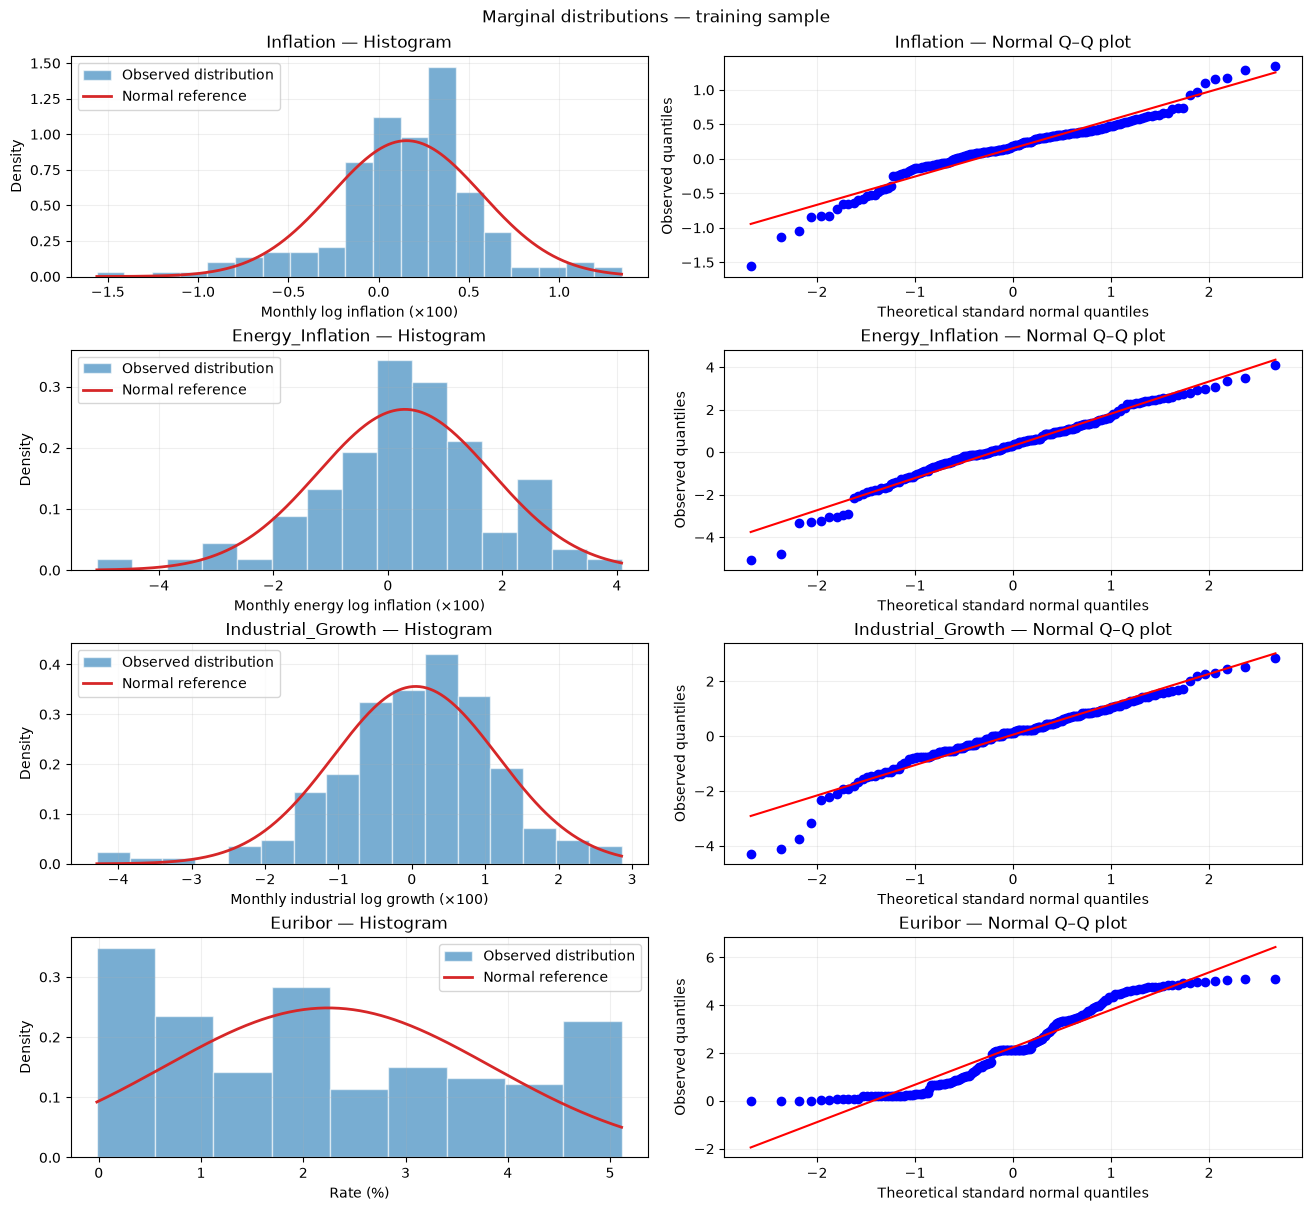

In [25]:
from scipy.stats import norm, probplot

features = [
    "Inflation",
    "Energy_Inflation",
    "Industrial_Growth",
    "Euribor",
]

# Scala utilizzata soltanto per la visualizzazione.
plot_data = train_data[features].copy()
plot_data[features[:3]] = 100 * plot_data[features[:3]]

units = {
    "Inflation": "Monthly log inflation (×100)",
    "Energy_Inflation": "Monthly energy log inflation (×100)",
    "Industrial_Growth": "Monthly industrial log growth (×100)",
    "Euribor": "Rate (%)",
}

fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 12),
    constrained_layout=True,
)

for row, feature in enumerate(features):
    values = plot_data[feature].dropna().to_numpy()

    # Istogramma e densità normale con media e deviazione standard campionarie.
    mean = values.mean()
    std = values.std(ddof=1)
    grid = np.linspace(values.min(), values.max(), 300)

    ax = axes[row, 0]
    ax.hist(
        values,
        bins="auto",
        density=True,
        color="tab:blue",
        alpha=0.6,
        edgecolor="white",
        label="Observed distribution",
    )
    ax.plot(
        grid,
        norm.pdf(grid, loc=mean, scale=std),
        color="tab:red",
        linewidth=2,
        label="Normal reference",
    )
    ax.set_title(f"{feature} — Histogram")
    ax.set_xlabel(units[feature])
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

    # Q–Q plot rispetto alla distribuzione normale.
    ax = axes[row, 1]
    probplot(values, dist="norm", plot=ax)
    ax.set_title(f"{feature} — Normal Q–Q plot")
    ax.set_xlabel("Theoretical standard normal quantiles")
    ax.set_ylabel(f"Observed quantiles")
    ax.grid(alpha=0.2)

fig.suptitle("Marginal distributions — training sample")
plt.savefig("../results/figures/hist_qq_plot.png")
plt.show()